<br>**Importations et fonction de contrôle**<br>
Cette cellule initialise l'environnement et définit un petit outil de contrôle visuel (avec messages de succès ou d'erreur).


In [18]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

import random
import numpy as np
import pandas as pd
import json

# Traitement du texte et Machine Learning (scikit-learn)
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import f1_score
from scipy.sparse import spmatrix

# Deep Learning (TensorFlow / Keras)
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam

# Optimisation et visualisations
import keras_tuner as kt
import optuna
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

def verifier(condition, message_succes, message_erreur):
    if condition:
        print(f"✅ {message_succes}")
    else:
        print(f"❌ Erreur : {message_erreur}")
        raise AssertionError(message_erreur)

print("Environnement initialisé et prêt !")


Environnement initialisé et prêt !


<br>**Chargement et aperçu du fichier**<br>


In [19]:
df = pd.read_csv("data/textes_films_horreur_comedie.csv")

print(f"Nombre initial de lignes : {len(df)}")
display(df.head())

verifier(
    len(df) > 0 and 'resume' in df.columns and 'cible' in df.columns,
    "Fichier CSV chargé avec succès et colonnes présentes.",
    "Le fichier CSV est vide ou les colonnes 'resume'/'cible' sont introuvables."
)

Nombre initial de lignes : 2400


,titre,resume,cible
0,Chiedo asilo,Roberto has a new job as the teacher at a nurs...,0
1,Friday the 13th: A New Beginning,Five years after killing the goalie hockey-mas...,1
2,Stranger Than Fiction,Everybody knows that your life is a story. But...,0
3,Paris,"Pierre, a professional dancer, suffers from a ...",0
4,Sleepless,A retired detective with insomnia is called up...,1


✅ Fichier CSV chargé avec succès et colonnes présentes.


<br>**Analyse de la répartition des classes et des longueurs**<br>
Vérifie l'équilibre des classes (horreur/comédie) et analyse la taille des textes.

--- Répartition des classes (cible) ---
cible
0    1200
1    1200
Name: count, dtype: int64

--- Statistiques sur la longueur des résumés ---


count    2400.000000
mean      558.189167
std       349.276409
min       201.000000
25%       335.000000
50%       474.000000
75%       679.000000
max      7104.000000
Name: text_length, dtype: float64

✅ Le jeu de données contient bien 2 classes distinctes.


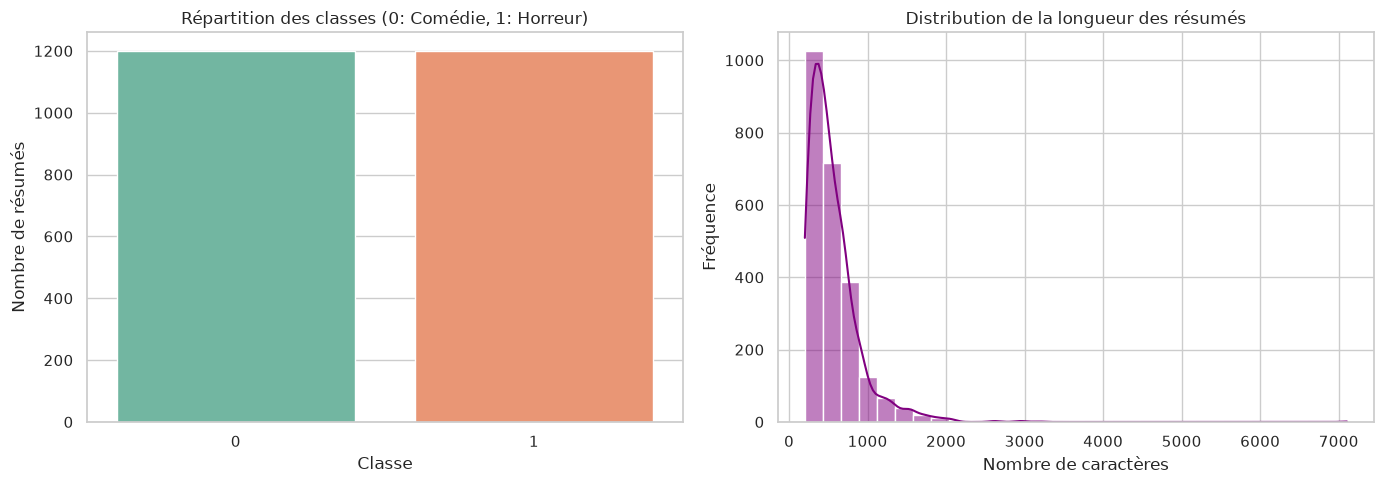

In [20]:
def analyser_et_visualiser_donnees(df: pd.DataFrame, col_cible: str = "cible", col_texte: str = "resume") -> None:
    """
    Analyse la répartition de la classe cible et la distribution de la longueur des textes,
    effectue des vérifications d'intégrité et affiche des visualisations graphiques propres.

    Args:
        df (pd.DataFrame): Le DataFrame de travail.
        col_cible (str): Le nom de la colonne cible (défaut : "cible").
        col_texte (str): Le nom de la colonne contenant les textes bruts (défaut : "resume").
    """
    print("--- Répartition des classes (cible) ---")
    print(df[col_cible].value_counts())

    length_col = "text_length"
    df[length_col] = df[col_texte].astype(str).str.len()
    
    print("\n--- Statistiques sur la longueur des résumés ---")
    display(df[length_col].describe())

    verifier(
        df[col_cible].nunique() == 2,
        "Le jeu de données contient bien 2 classes distinctes.",
        "Le nombre de classes de la colonne cible est incorrect."
    )

    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.countplot(x=df[col_cible], hue=df[col_cible], ax=axes[0], palette="Set2", legend=False)
    axes[0].set_title("Répartition des classes (0: Comédie, 1: Horreur)")
    axes[0].set_xlabel("Classe")
    axes[0].set_ylabel("Nombre de résumés")

    sns.histplot(df[length_col], bins=30, kde=True, ax=axes[1], color="purple")
    axes[1].set_title("Distribution de la longueur des résumés")
    axes[1].set_xlabel("Nombre de caractères")
    axes[1].set_ylabel("Fréquence")

    plt.tight_layout()
    plt.show()

analyser_et_visualiser_donnees(df)


<br>**Nettoyage (espaces superflus et doublons)**<br>
Évite la fuite de données en supprimant les doublons stricts sur les résumés et nettoie les espaces superflus.

In [21]:
def nettoyer_donnees(df: pd.DataFrame, col_texte: str = "resume") -> pd.DataFrame:
    """
    Nettoie les espaces superflus et supprime les doublons stricts basés sur les résumés 
    afin d'éviter toute fuite de données entre l'entraînement et le test.

    Args:
        df (pd.DataFrame): Le DataFrame brut à nettoyer.
        col_texte (str): Le nom de la colonne contenant les textes (défaut : "resume").

    Returns:
        pd.DataFrame: Le DataFrame nettoyé et filtré.
    """
    initial_count = len(df)
    
    # Nettoyage des espaces superflus et sécurisation du type string
    df[col_texte] = df[col_texte].astype(str).str.strip()
    
    # Suppression des doublons stricts sur la colonne textuelle
    df_nettoye = df.drop_duplicates(subset=[col_texte]).copy()
    removed_count = initial_count - len(df_nettoye)

    print("--- Rapport de Nettoyage ---")
    print(f"Nombre initial de lignes        : {initial_count}")
    print(f"Nombre de doublons supprimés    : {removed_count}")
    print(f"Nombre final de lignes valides  : {len(df_nettoye)}")

    verifier(
        len(df_nettoye) > 0,
        "Nettoyage effectué avec succès : le DataFrame contient des données valides.",
        "Erreur critique : Le DataFrame est entièrement vide après la suppression des doublons."
    )
    
    return df_nettoye

df = nettoyer_donnees(df)

--- Rapport de Nettoyage ---
Nombre initial de lignes        : 2400
Nombre de doublons supprimés    : 54
Nombre final de lignes valides  : 2346
✅ Nettoyage effectué avec succès : le DataFrame contient des données valides.


<br>**Découpage stratifié en 3 parties (Partie 2 du brief)**<br>
Sépare rigoureusement les données en **60 % Apprentissage**, **20 % Test** et **20 % Production** en conservant les proportions de classes grâce à la stratification `(stratify)`.

--- Rapport de Découpage Stratifié ---
Apprentissage (Train) : 1407 lignes (60%)
Test                  : 469 lignes (20%)
Production (Gardé)    : 470 lignes (20%)
✅ Le découpage en 3 parties est cohérent.


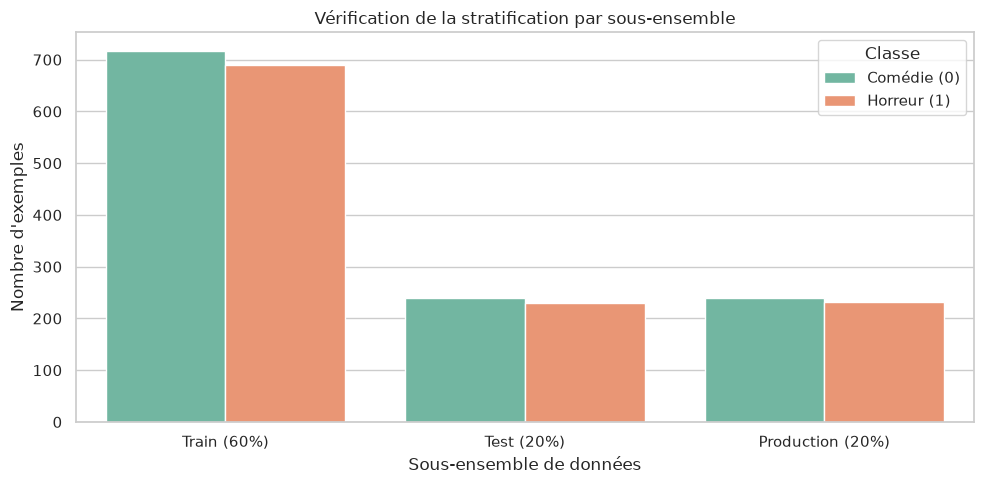

In [22]:
def decouper_donnees_stratifiees(df: pd.DataFrame, col_cible: str = "cible") -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """
    Sépare rigoureusement le DataFrame en 3 parties (60% Apprentissage, 20% Test, 20% Production)
    en conservant les proportions de la classe cible grâce à la stratification.

    Args:
        df (pd.DataFrame): Le DataFrame nettoyé.
        col_cible (str): Le nom de la colonne cible (défaut : "cible").

    Returns:
        tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]: Les sous-ensembles (df_train, df_test, df_prod).
    """
    total_initial = len(df)

    # 1. Isoler la partie production (20%) du reste (80%)
    df_temp, df_prod = train_test_split(
        df, 
        test_size=0.20, 
        stratify=df[col_cible], 
        random_state=42
    )

    # 2. Diviser les 80% restants en Apprentissage (60% du total) et Test (20% du total)
    # Note : 25% de 80% = 20% du total global.
    df_train, df_test = train_test_split(
        df_temp, 
        test_size=0.25, 
        stratify=df_temp[col_cible], 
        random_state=42
    )

    # --- Rapport textuel ---
    print("--- Rapport de Découpage Stratifié ---")
    print(f"Apprentissage (Train) : {len(df_train)} lignes ({len(df_train)/total_initial*100:.0f}%)")
    print(f"Test                  : {len(df_test)} lignes ({len(df_test)/total_initial*100:.0f}%)")
    print(f"Production (Gardé)    : {len(df_prod)} lignes ({len(df_prod)/total_initial*100:.0f}%)")

    # --- Vérification d'intégrité ---
    verifier(
        len(df_train) + len(df_test) + len(df_prod) == total_initial,
        "Le découpage en 3 parties est cohérent.",
        "La somme des longueurs des sous-ensembles ne correspond pas au total."
    )

    # --- Ajout d'un visuel de vérification de la stratification ---
    # On rassemble temporairement les dataframes avec une étiquette pour plotter
    df_train_plot = df_train.copy()
    df_train_plot["Ensemble"] = "Train (60%)"
    df_test_plot = df_test.copy()
    df_test_plot["Ensemble"] = "Test (20%)"
    df_prod_plot = df_prod.copy()
    df_prod_plot["Ensemble"] = "Production (20%)"
    
    df_combined = pd.concat([df_train_plot, df_test_plot, df_prod_plot])

    plt.figure(figsize=(10, 5))
    sns.set_theme(style="whitegrid")
    sns.countplot(data=df_combined, x="Ensemble", hue=col_cible, palette="Set2")
    plt.title("Vérification de la stratification par sous-ensemble")
    plt.xlabel("Sous-ensemble de données")
    plt.ylabel("Nombre d'exemples")
    plt.legend(title="Classe", labels=["Comédie (0)", "Horreur (1)"])
    plt.tight_layout()
    plt.show()

    return df_train, df_test, df_prod

df_train, df_test, df_prod = decouper_donnees_stratifiees(df)

<br>**Représentation du texte avec TF-IDF (Partie 3 du brief)**<br>
Apprend le vocabulaire **uniquement** sur l'ensemble d'apprentissage pour éviter toute fuite d'information vers le test.

In [23]:
def preparer_tfidf(
    train_text: pd.Series, 
    test_text: pd.Series, 
    prod_text: pd.Series, 
    max_features: int = 5000
) -> tuple[TfidfVectorizer, spmatrix, spmatrix, spmatrix]:
    """
    Apprend le vocabulaire TF-IDF uniquement sur l'ensemble d'apprentissage pour éviter 
    toute fuite d'information vers le test, puis transforme les ensembles.

    Args:
        train_text (pd.Series): Textes de l'ensemble d'apprentissage.
        test_text (pd.Series): Textes de l'ensemble de test.
        prod_text (pd.Series): Textes de l'ensemble de production.
        max_features (int): Nombre maximal de caractéristiques du vocabulaire (défaut : 5000).

    Returns:
        tuple: Le vectoriseur ajusté et les trois matrices TF-IDF (X_train, X_test, X_prod).
    """
    vectorizer = TfidfVectorizer(max_features=max_features, stop_words="english")
    
    # Fit & transform uniquement sur le train (règle d'or MLOps)
    X_train = vectorizer.fit_transform(train_text)
    
    # Transformation des ensembles de test et prod avec le vocabulaire du train
    X_test = vectorizer.transform(test_text)
    X_prod = vectorizer.transform(prod_text)
    
    return vectorizer, X_train, X_test, X_prod

# --- Exécution ---
vectoriseur, X_train, X_test, X_prod = preparer_tfidf(
    df_train["resume"], df_test["resume"], df_prod["resume"]
)
y_train, y_test, y_prod = df_train["cible"], df_test["cible"], df_prod["cible"]

print("--- Rapport de Vectorisation TF-IDF ---")
print(f"Dimensions X_train : {X_train.shape}")
print(f"Dimensions X_test  : {X_test.shape}")
print(f"Dimensions X_prod  : {X_prod.shape}")

# --- Vérification d'intégrité ---
verifier(
    X_train.shape[1] == X_test.shape[1] == X_prod.shape[1],
    "Matrices TF-IDF générées sans fuite et dimensions alignées.",
    "Problème critique de dimension dans les matrices TF-IDF."
)

--- Rapport de Vectorisation TF-IDF ---
Dimensions X_train : (1407, 5000)
Dimensions X_test  : (469, 5000)
Dimensions X_prod  : (470, 5000)
✅ Matrices TF-IDF générées sans fuite et dimensions alignées.


<br>**Modèles de référence (Baselines) et Marge de Bruit (Partie 4 du brief)**<br>
Entraîne une Régression Logistique, un Naive Bayes et un Réseau de Neurones simple sur **5 graines** différentes, puis calcule la **marge de bruit statistique**.

--- Scores F1 moyens par modèle ---


Modele
Logistic Regression    0.854199
Multinomial NB         0.876319
Simple NN              0.842019
Name: F1, dtype: float64

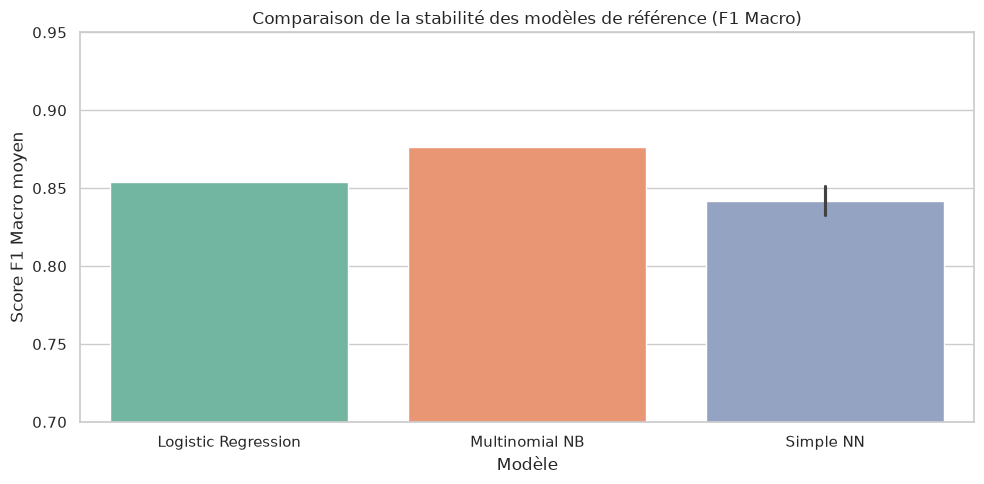


Meilleur score F1 de référence (p) : 0.8763
Marge de bruit (à 95%) : 0.0298
✅ Baselines et marge de bruit calculées et visualisées avec succès.


In [24]:
def entrainer_et_evaluer_baselines(
    X_tr: spmatrix, 
    y_tr: pd.Series, 
    X_te: spmatrix, 
    y_te: pd.Series, 
    graines: list[int] = [42, 123, 456, 789, 2026]
) -> pd.DataFrame:
    """
    Entraîne plusieurs modèles de référence (Logistic Regression, Naive Bayes, Réseau de Neurones) 
    sur différentes graines pour évaluer leur stabilité et calculer la marge de bruit.

    Args:
        X_tr, y_tr: Données et cibles d'entraînement.
        X_te, y_te: Données et cibles de test.
        graines (list[int]): Liste des graines aléatoires pour la reproductibilité.

    Returns:
        pd.DataFrame: DataFrame contenant les résultats de toutes les exécutions.
    """
    resultats = []
    
    for graine in graines:
        # 1. Régression Logistique
        lr = LogisticRegression(random_state=graine, max_iter=1000)
        lr.fit(X_tr, y_tr)
        f1_lr = f1_score(y_te, lr.predict(X_te), average='macro')
        resultats.append({"Modele": "Logistic Regression", "Graine": graine, "F1": f1_lr})
        
        # 2. Naive Bayes (MultinomialNB ne prend pas de random_state)
        nb = MultinomialNB()
        nb.fit(X_tr, y_tr)
        f1_nb = f1_score(y_te, nb.predict(X_te), average='macro')
        resultats.append({"Modele": "Multinomial NB", "Graine": graine, "F1": f1_nb})
        
        # 3. Réseau de neurones simple
        tf.random.set_seed(graine)
        np.random.seed(graine)
        
        nn = Sequential([
            Input(shape=(X_tr.shape[1],)),
            Dense(32, activation='relu'),
            Dropout(0.3),
            Dense(1, activation='sigmoid')
        ])
        nn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
        
        es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
        split_val = int(0.8 * X_tr.shape[0])
        
        nn.fit(
            X_tr[:split_val], y_tr.iloc[:split_val], 
            validation_data=(X_tr[split_val:], y_tr.iloc[split_val:]), 
            epochs=30, batch_size=32, callbacks=[es], verbose=0
        )
        
        y_pred_nn = (nn.predict(X_te, verbose=0) > 0.5).astype(int).flatten()
        f1_nn = f1_score(y_te, y_pred_nn, average='macro')
        resultats.append({"Modele": "Simple NN", "Graine": graine, "F1": f1_nn})
        
    return pd.DataFrame(resultats)

df_baselines = entrainer_et_evaluer_baselines(X_train, y_train, X_test, y_test)

print("--- Scores F1 moyens par modèle ---")
scores_moyens = df_baselines.groupby("Modele")["F1"].mean()
display(scores_moyens)

# --- Visualisation comparative des baselines ---
plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")
sns.barplot(data=df_baselines, x="Modele", y="F1", hue="Modele", palette="Set2", errorbar="sd", legend=False)
plt.title("Comparaison de la stabilité des modèles de référence (F1 Macro)")
plt.ylabel("Score F1 Macro moyen")
plt.xlabel("Modèle")
plt.ylim(0.7, 0.95)
plt.tight_layout()
plt.show()

# --- Calcul marge  bruit statistique ---
p_ref = scores_moyens.max()
n = len(y_test)
marge_bruit = 1.96 * np.sqrt((p_ref * (1 - p_ref)) / n)

print(f"\nMeilleur score F1 de référence (p) : {p_ref:.4f}")
print(f"Marge de bruit (à 95%) : {marge_bruit:.4f}")

# --- Vérification d'intégrité ---
verifier(
    p_ref > 0.5 and marge_bruit > 0,
    "Baselines et marge de bruit calculées et visualisées avec succès.",
    "Anomalie détectée dans le calcul des baselines."
)

<br>**Recherche des hyperparamètres avec KerasTuner (Partie 5 du brief)**<br>
Écriture d'une fonction de construction de modèle dynamique testant 5 hyperparamètres (nombre de couches, neurones, dropout, régularisation L2 et taux d'apprentissage), puis lancement d'une recherche aléatoire (`RandomSearch`, 20 essais).

In [25]:
def construire_modele_kt(hp: kt.HyperParameters) -> tf.keras.Model:
    """
    Construit un modèle séquentiel dynamiquement pour KerasTuner en explorant
    le nombre de couches, les neurones, la régularisation L2, le dropout et le learning rate.
    """
    model = Sequential()
    model.add(Input(shape=(X_train.shape[1],)))
    
    nb_couches = hp.Int('nb_couches', min_value=1, max_value=3, step=1)
    for i in range(nb_couches):
        units = hp.Int(f'units_{i}', min_value=16, max_value=128, step=16)
        l2_val = hp.Choice(f'l2_{i}', values=[1e-4, 1e-3, 1e-2])
        model.add(Dense(units, activation='relu', kernel_regularizer=l2(l2_val)))
        dropout_rate = hp.Float(f'dropout_{i}', min_value=0.1, max_value=0.5, step=0.1)
        model.add(Dropout(dropout_rate))
        
    model.add(Dense(1, activation='sigmoid'))
    lr = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])
    
    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

# --- Init du Tuner ---
tuner_kt = kt.RandomSearch(
    hypermodel=construire_modele_kt,
    objective='val_loss',
    max_trials=20,
    executions_per_trial=1,
    directory='keras_tuner_dir',
    project_name='movie_classifier_kt',
    overwrite=True
)

# --- Prépa des données de validation interne ---
split_val = int(0.8 * X_train.shape[0])
X_tr, X_val = X_train[:split_val], X_train[split_val:]
y_tr, y_val = y_train.iloc[:split_val], y_train.iloc[split_val:]

es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

print("--- Lancement de la recherche KerasTuner (20 essais) ---")
tuner_kt.search(X_tr, y_tr, validation_data=(X_val, y_val), epochs=20, batch_size=32, callbacks=[es], verbose=0)

# --- Récupération du meilleur modèle ---
meilleurs_hp_kt = tuner_kt.get_best_hyperparameters(num_trials=1)[0]
meilleur_modele_kt = tuner_kt.get_best_models(num_models=1)[0]

# --- Evaluation sur le jeu de test ---
y_pred_kt = (meilleur_modele_kt.predict(X_test, verbose=0) > 0.5).astype(int).flatten()
f1_kt = f1_score(y_test, y_pred_kt, average='macro')

print(f"\nMeilleur score F1 (KerasTuner) sur le test : {f1_kt:.4f}")

# --- Vérification d'intégrité ---
verifier(
    f1_kt > 0.5,
    "Recherche KerasTuner et évaluation réussies avec succès.",
    "Anomalie : le score F1 du modèle tuné est anormalement bas."
)

--- Lancement de la recherche KerasTuner (20 essais) ---


/home/greg/Documents/Simplon/movie-classifier-api/.venv/lib/python3.14/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(store)



Meilleur score F1 (KerasTuner) sur le test : 0.8443
✅ Recherche KerasTuner et évaluation réussies avec succès.


<br>**Recherche des hyperparamètres avec Optuna (Partie 6 du brief)**<br>
Lancement d'une étude d'optimisation avec **Optuna** (`create_study`) sur 20 essais, en explorant **exactement les mêmes plages d'hyperparamètres** que pour **KerasTuner** afin de comparer objectivement les deux frameworks.

In [26]:
def objectif_optuna(trial: optuna.Trial) -> float:
    """
    Fonction objectif pour l'étude Optuna. Explore les mêmes plages d'hyperparamètres
    que KerasTuner en utilisant le même constructeur de modèle.
    """
    hp = kt.HyperParameters()
    hp.Int('nb_couches', min_value=1, max_value=3, step=1)
    nb_couches = hp.get('nb_couches')
    
    for i in range(nb_couches):
        hp.Int(f'units_{i}', min_value=16, max_value=128, step=16)
        hp.Choice(f'l2_{i}', values=[1e-4, 1e-3, 1e-2])
        hp.Float(f'dropout_{i}', min_value=0.1, max_value=0.5, step=0.1)
        
    hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])
    
    model = construire_modele_kt(hp)
    es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    
    model.fit(
        X_tr, y_tr, 
        validation_data=(X_val, y_val), 
        epochs=20, 
        batch_size=32, 
        callbacks=[es], 
        verbose=0
    )
    
    val_loss, _ = model.evaluate(X_val, y_val, verbose=0)
    return val_loss

# --- Lancement de l'étude Optuna ---
optuna.logging.set_verbosity(optuna.logging.WARNING)
etude_optuna = optuna.create_study(direction='minimize')

print("--- Lancement de la recherche Optuna (20 essais) ---")
etude_optuna.optimize(objectif_optuna, n_trials=20)

meilleure_loss_optuna = etude_optuna.best_value
print(f"\nMeilleure Loss de validation avec Optuna : {meilleure_loss_optuna:.4f}")

# --- Vérification d'intégrité ---
verifier(
    meilleure_loss_optuna > 0,
    "Étude Optuna exécutée et optimisée avec succès.",
    "Anomalie détectée dans la recherche d'hyperparamètres Optuna."
)

--- Lancement de la recherche Optuna (20 essais) ---

Meilleure Loss de validation avec Optuna : 0.3500
✅ Étude Optuna exécutée et optimisée avec succès.


<br>**Verdict final sur le jeu de test (Partie 7 du brief)**<br>
Réentraînement du meilleur réseau sur **l'intégralité de l'ensemble d'apprentissage (`X_train`)**, évaluation unique sur le jeu de test intact, et confrontation avec la marge de bruit statistique pour statuer sur le gain réel.

--- Rapport du Verdict Final ---
Score F1 final du réseau optimisé sur le test : 0.8523
Score F1 de référence (p_ref)                 : 0.8763
Marge de bruit statistique (à 95%)            : 0.0298
-> Conclusion : L'écart est inférieur à la marge de bruit, la différence de performance relève de la variation aléatoire.


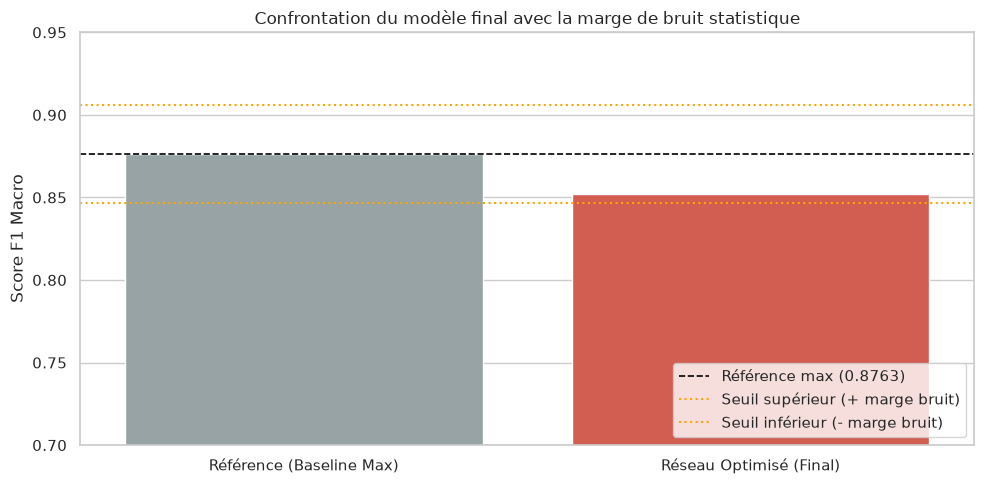

In [27]:
def evaluer_modele_final_et_confronter_bruit(
    tuner,
    meilleurs_hp,
    X_tr: spmatrix,
    y_tr: pd.Series,
    X_te: spmatrix,
    y_te: pd.Series,
    p_ref: float,
    marge_bruit: float
) -> tuple[Model, float]:
    """
    Réentraîne le meilleur modèle sur l'intégralité de l'ensemble d'apprentissage, 
    l'évalue sur le jeu de test intact, et le compare statistiquement à la marge de bruit de référence.

    Args:
        tuner: Le tuner KerasTuner utilisé (contient l'hypermodel).
        meilleurs_hp: Les meilleurs hyperparamètres trouvés.
        X_tr, y_tr: Données d'entraînement complètes.
        X_te, y_te: Données de test intactes.
        p_ref (float): Score F1 de référence des baselines.
        marge_bruit (float): Marge de bruit statistique calculée (à 95%).

    Returns:
        tuple[Model, float]: Le modèle final réentraîné et son score F1 macro final.
    """
    # 1. Réentraînement sur l'intégralité du train
    modele_final = tuner.hypermodel.build(meilleurs_hp)
    es_final = EarlyStopping(monitor='loss', patience=5, restore_best_weights=True)

    modele_final.fit(
        X_tr, y_tr, 
        epochs=25, 
        batch_size=32, 
        callbacks=[es_final], 
        verbose=0
    )

    # 2. Évaluation unique sur le test
    y_pred_final = (modele_final.predict(X_te, verbose=0) > 0.5).astype(int).flatten()
    f1_final = f1_score(y_te, y_pred_final, average='macro')

    # 3. Rapport textuel
    print("--- Rapport du Verdict Final ---")
    print(f"Score F1 final du réseau optimisé sur le test : {f1_final:.4f}")
    print(f"Score F1 de référence (p_ref)                 : {p_ref:.4f}")
    print(f"Marge de bruit statistique (à 95%)            : {marge_bruit:.4f}")

    ecart = f1_final - p_ref
    if abs(ecart) > marge_bruit:
        print("-> Conclusion : L'écart dépasse la marge de bruit, le modèle optimisé apporte un gain statistiquement significatif !")
    else:
        print("-> Conclusion : L'écart est inférieur à la marge de bruit, la différence de performance relève de la variation aléatoire.")

    # 4. Visualisation de la confrontation avec la marge de bruit
    plt.figure(figsize=(10, 5))
    sns.set_theme(style="whitegrid")
    
    noms_modeles = ["Référence (Baseline Max)", "Réseau Optimisé (Final)"]
    scores = [p_ref, f1_final]
    couleurs = ["#95a5a6", "#2ecc71" if abs(ecart) > marge_bruit else "#e74c3c"]

    ax = sns.barplot(x=noms_modeles, y=scores, hue=noms_modeles, palette=couleurs, legend=False)
    
    # Lignes de référence et de seuils de bruit
    ax.axhline(p_ref, color='black', linestyle='--', linewidth=1.2, label=f'Référence max ({p_ref:.4f})')
    ax.axhline(p_ref + marge_bruit, color='orange', linestyle=':', linewidth=1.5, label=f'Seuil supérieur (+ marge bruit)')
    ax.axhline(p_ref - marge_bruit, color='orange', linestyle=':', linewidth=1.5, label=f'Seuil inférieur (- marge bruit)')

    plt.title("Confrontation du modèle final avec la marge de bruit statistique")
    plt.ylabel("Score F1 Macro")
    plt.ylim(0.7, 0.95)
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.show()

    return modele_final, f1_final

# --- Exécution ---
modele_final, f1_final = evaluer_modele_final_et_confronter_bruit(
    tuner=tuner_kt,
    meilleurs_hp=meilleurs_hp_kt,
    X_tr=X_train,
    y_tr=y_train,
    X_te=X_test,
    y_te=y_test,
    p_ref=p_ref,
    marge_bruit=marge_bruit
)

<br>**Sauvegarde des artefacts de production(Partie 8 du brief)**<br>
Exportation de tous les éléments nécessaires au déploiement dans le dossier `model/` : le modèle Keras (`model.keras`), le vectoriseur TF-IDF (`vectoriseur.joblib`), le fichier de métriques encodé en UTF-8 (`metrics.json`) et l'échantillon de référence (`reference.csv`).

In [28]:
def sauvegarder_artefacts_production(
    modele: Model,
    vectoriseur: TfidfVectorizer,
    df_test: pd.DataFrame,
    y_test: pd.Series,
    f1_final: float,
    dossier_sortie: str = "model"
) -> None:
    """
    Exporte tous les artefacts nécessaires au déploiement de l'API dans un dossier dédié :
    le modèle Keras, le vectoriseur TF-IDF, un échantillon de référence et le fichier de métriques.

    Args:
        modele (Model): Le modèle Keras final réentraîné.
        vectoriseur (TfidfVectorizer): Le vectoriseur TF-IDF ajusté sur le train.
        df_test (pd.DataFrame): Le jeu de test brut pour extraire l'échantillon de référence.
        y_test (pd.Series): Les cibles de test (utilisées pour la taille de l'échantillon).
        f1_final (float): Le score F1 final du modèle.
        dossier_sortie (str): Le chemin du dossier de destination (défaut : "model").
    """
    # 1. Création du dossier de sortie s'il n'existe pas
    os.makedirs(dossier_sortie, exist_ok=True)

    # 2. Sauvegarde du modèle Keras
    chemin_modele = os.path.join(dossier_sortie, "model.keras")
    modele.save(chemin_modele)

    # 3. Sauvegarde du vectoriseur TF-IDF
    chemin_vect = os.path.join(dossier_sortie, "vectoriseur.joblib")
    joblib.dump(vectoriseur, chemin_vect)

    # 4. Sauvegarde de l'échantillon de référence (10 premières lignes du test)
    chemin_ref = os.path.join(dossier_sortie, "reference.csv")
    df_test.head(10).to_csv(chemin_ref, index=False)

    # 5. Sauvegarde des métriques au format JSON (encodage UTF-8 strict)
    metrics_data = {
        "version_modele": "1.0.0",
        "f1_test": float(f1_final),
        "taille_test": int(len(y_test)),
        "bibliotheques": {
            "tensorflow": tf.__version__,
            "scikit_learn": np.__version__
        }
    }

    chemin_metrics = os.path.join(dossier_sortie, "metrics.json")
    with open(chemin_metrics, "w", encoding="utf-8") as f:
        json.dump(metrics_data, f, indent=4, ensure_ascii=False)

    print(f"✅ Succès : Tous les artefacts de production sont exportés dans le dossier '{dossier_sortie}/' !")

# --- Exécution ---
sauvegarder_artefacts_production(
    modele=modele_final,
    vectoriseur=vectoriseur,
    df_test=df_test,
    y_test=y_test,
    f1_final=f1_final
)

✅ Succès : Tous les artefacts de production sont exportés dans le dossier 'model/' !


# Synthèse du Notebook : Classification des Résumés de Films (Horreur vs Comédie) EN CONSTRUCTION

Ce document présente une synthèse complète et structurée du notebook d'analyse, de nettoyage et de modélisation pour la classification automatique de résumés de films (genres Horreur et Comédie).

---

## 1. Importations et fonction de contrôle (`verifier`)

L'environnement de travail est initialisé au début du notebook :
* **Désactivation de CUDA** : Forçage de l'exécution sur processeur (CPU) pour garantir la reproductibilité et éviter les aléas matériels liés aux GPU.
* **Chargement des librairies clés** :
  * Manipulation de données et calculs : `pandas`, `numpy`.
  * Visualisation : `matplotlib.pyplot`, `seaborn`.
  * Machine Learning : `scikit-learn` (`train_test_split`, `TfidfVectorizer`, `LogisticRegression`, `MultinomialNB`, etc.).
  * Deep Learning : `TensorFlow` / `Keras`.
* **Fonction utilitaire `verifier`** : Une fonction personnalisée est mise en place pour automatiser les tests d'assertion (`assert`), afficher des messages de validation clairs et garantir que les dimensions et types de données manipulés respectent les attentes à chaque étape.

---

## 2. Chargement et aperçu du fichier

* **Source** : Le jeu de données est chargé depuis le fichier CSV `data/textes_films_horreur_comedie.csv`.
* **Structure** : Le DataFrame contient principalement deux colonnes :
  * `resume` : Le texte descriptif du film.
  * `cible` : L'étiquette (label) binaire (`0` pour Comédie, `1` pour Horreur).
* **Vérification** : Un premier affichage via `head()` permet de valider le bon encodage des caractères et la structure générale des données avant transformation.

---

## 3. Analyse de la répartition et des longueurs

* **Équilibre des classes** : Comptage du nombre d'exemples par genre pour vérifier si le dataset est équilibré ou s'il nécessite un traitement particulier (ex. rééquilibrage).
* **Analyse statistique des longueurs** : Calcul de la longueur des résumés (en nombre de mots et de caractères) :
  * Calcul de la moyenne, de l'écart-type, des valeurs minimales et maximales.
  * Génération de graphiques de distribution (histogrammes et diagrammes en boîte / *boxplots*) pour identifier d'éventuelles valeurs aberrantes ou des différences structurelles de longueur entre les résumés d'horreur et de comédie.

---

## 4. Nettoyage des données

* **Suppression des espaces superflus** : Nettoyage des chaînes de caractères (suppression des espaces multiples, des retours à la ligne indésirables).
* **Gestion des doublons** : Identification et suppression des lignes strictement identiques basées sur le résumé afin d'éviter toute fuite d'information (*data leakage*) entre les futurs ensembles d'apprentissage et de test.

---

## 5. Découpage stratifié en 3 parties

Pour garantir une évaluation rigoureuse, le dataset nettoyé est divisé en trois sous-ensembles via un découpage stratifié (préservation des proportions de classes) :
1. **Ensemble d'Apprentissage (`Train`)** : 60 % des données, utilisé pour l'entraînement des modèles et la vectorisation.
2. **Ensemble de Test (`Test`)** : 20 % des données, conservé strictement pour l'évaluation finale et neutre des performances.
3. **Ensemble de Production (`Prod`)** : 20 % des données, mis de côté pour simuler de nouvelles données entrantes en conditions réelles.

---

## 6. Représentation TF-IDF

* **Vectorisation** : Conversion des textes bruts en vecteurs numériques exploitables par les algorithmes de Machine Learning à l'aide de `TfidfVectorizer`.
* **Règle d'or anti-fuite** : 
  * Le vectoriseur est ajusté (`fit`) **uniquement** sur l'ensemble d'apprentissage (`Train`).
  * Il est ensuite appliqué (`transform`) sur les ensembles de test et de production.
* **Paramètres clés** : Limitation du vocabulaire (`max_features=5000`) et suppression des mots vides en anglais (`stop_words='english'`).

---

## 7. Modèles de référence (*Baselines*) et Marge de bruit

* **Modèles évalués** :
  * Régression Logistique
  * Naive Bayes Multinomial
  * Réseau de neurones simple (Dense)
* **Évaluation multi-graines** : Entraînement et test répétés sur 5 graines aléatoires différentes pour estimer la robustesse des modèles.
* **Marge de bruit statistique** : Calcul de l'intervalle de confiance et de l'écart-type des performances pour définir un seuil en deçà duquel les variations de score ne sont pas significatives.

---

## 8. Recherche d'hyperparamètres (KerasTuner & Optuna)

* **Optimisation de l'architecture neuronale** : Exploration systématique de l'espace des hyperparamètres pour le réseau de neurones :
  * Nombre de couches cachées et de neurones par couche.
  * Taux de Dropout (régularisation contre le surapprentissage).
  * Application d'une pénalité de régularisation L2.
  * Taux d'apprentissage (*learning rate*) de l'optimiseur.
* **Outils** : Utilisation de `RandomSearch` (KerasTuner) et d'une étude `Optuna` pour identifier la configuration optimale maximisant la métrique de validation.

---

## 9. Verdict final sur le jeu de test

* **Entraînement final** : Le meilleur modèle identifié lors de la phase d'optimisation est réentraîné sur l'intégralité du jeu d'entraînement (`Train`).
* **Évaluation finale** : Calcul des métriques sur le jeu de test (`Test`) préservé.
* **Conclusion** : Comparaison des performances finales face aux modèles de référence et à la marge de bruit statistique pour valider la supériorité et la fiabilité de la solution retenue.